# Image retrieval by colour (query DVI2 -> database DVI1)

1. **Indexing** - compute the colour histogram and dominant colours of every image in `DVI1` and store them in `histograms.json` / `dominant_colors.json`.
2. **Query** - choose an image from `DVI2`, compute its features and rank the database with three metrics: histogram, dominant colours and a global metric (normalised weighted sum).
3. **Evaluation** - run every query and measure precision@4 (each category has 4 images in the database).

The helper functions live in [`features.py`](features.py).

In [1]:
import os
import random

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from features import (calculate_color_histogram, category, dominant_color_distance,
                      extract_features, find_dominant_colors, histogram_distance,
                      list_images, load_json, rank, save_json)

DATABASE_DIR = "DVI1"  # 16 reference images, 4 per category
QUERY_DIR = "DVI2"     # 1 query image per category

## 1. Indexing - compute and save the features of DVI1

In [2]:
histogram_data, dominant_color_data = extract_features(DATABASE_DIR, k=20, threshold=0.05)
save_json(histogram_data, "histograms.json")
save_json(dominant_color_data, "dominant_colors.json")
print(f"Indexed {len(histogram_data)} images -> histograms.json, dominant_colors.json")

Indexed 16 images -> histograms.json, dominant_colors.json


## 2. Query
Set `QUERY` to a file name of `DVI2` (e.g. `'8994.jpg'`) or leave `None` for a random one. `WEIGHT` is the share of the histogram distance in the global metric.

In [3]:
QUERY = None
WEIGHT = 0.5
TOP_N = 6

histogram_data = load_json("histograms.json")
dominant_color_data = load_json("dominant_colors.json")

query_paths = list_images(QUERY_DIR)
selected_image_path = os.path.join(QUERY_DIR, QUERY) if QUERY else random.choice(query_paths)
selected_image = os.path.basename(selected_image_path)

chosen_histogram = calculate_color_histogram(selected_image_path)
chosen_dominant_colors = find_dominant_colors(selected_image_path)
rankings = rank(chosen_histogram, chosen_dominant_colors, histogram_data, dominant_color_data, WEIGHT)
print("Query:", selected_image, f"({category(selected_image)})")

Query: 8994.jpg (tulip fields)


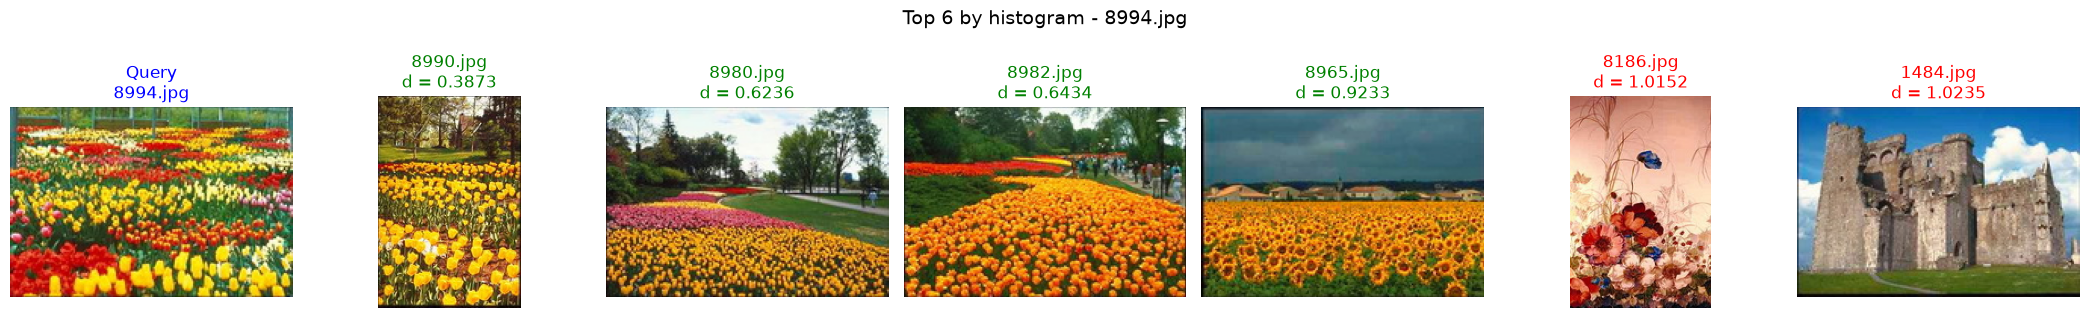

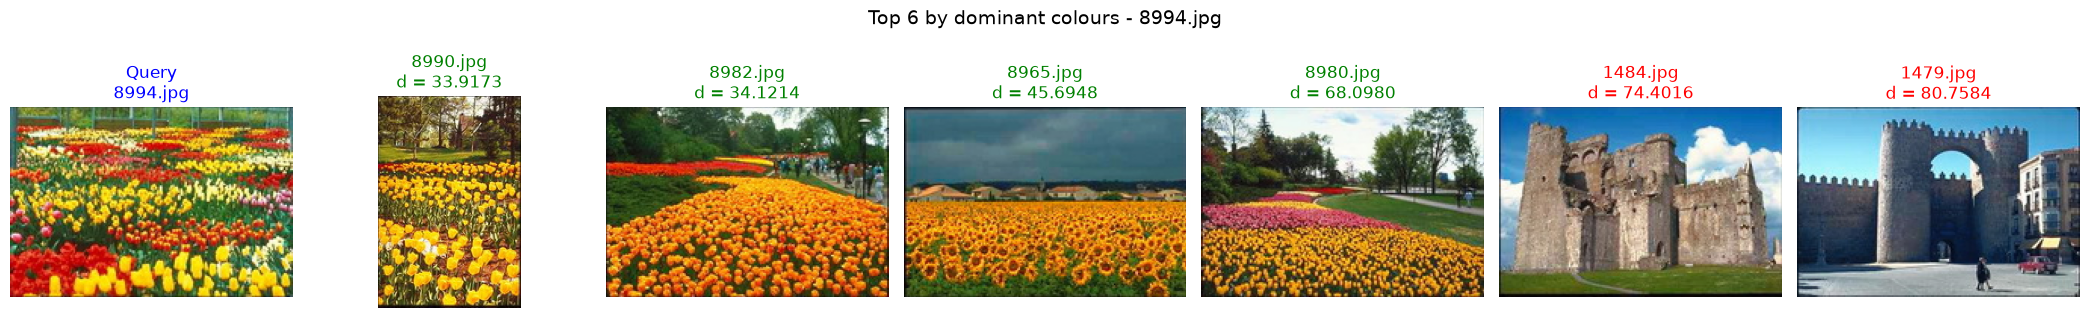

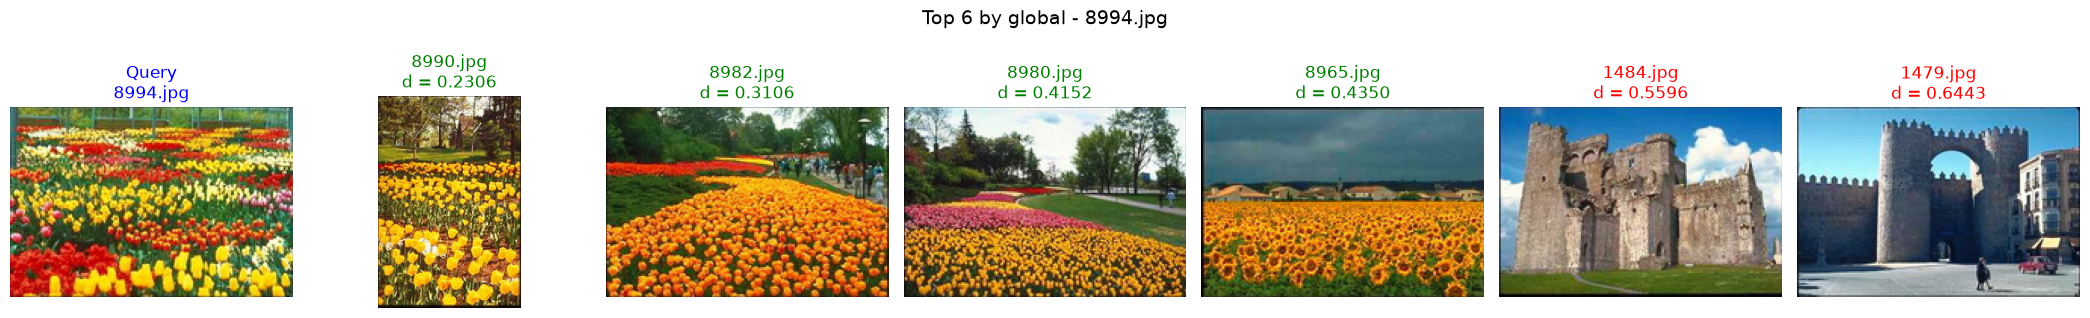

In [4]:
def plot_similar_images(query_path, results, title):
    query_name = os.path.basename(query_path)
    fig, axes = plt.subplots(1, len(results) + 1, figsize=(3 * (len(results) + 1), 3.2))
    fig.suptitle(title, fontsize=14)
    axes[0].imshow(Image.open(query_path))
    axes[0].set_title(f"Query\n{query_name}", color="blue")
    for ax, (name, dist) in zip(axes[1:], results):
        same = category(name) == category(query_name)
        ax.imshow(Image.open(os.path.join(DATABASE_DIR, name)))
        ax.set_title(f"{name}\nd = {dist:.4f}", color="green" if same else "red")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


for metric, results in rankings.items():
    plot_similar_images(selected_image_path, results[:TOP_N], f"Top {TOP_N} by {metric} - {selected_image}")

Green: same category as the query, red: different category.

## 3. Evaluation - precision@4 for every query and metric

In [5]:
K = 4
scores = {}
for path in query_paths:
    name = os.path.basename(path)
    r = rank(calculate_color_histogram(path), find_dominant_colors(path),
             histogram_data, dominant_color_data, WEIGHT)
    scores[name] = {m: sum(category(n) == category(name) for n, _ in res[:K]) / K for m, res in r.items()}

metrics = list(next(iter(scores.values())))
print(f"{'query':10s} {'category':14s}" + "".join(f"{m:>18s}" for m in metrics))
for name, s in scores.items():
    print(f"{name:10s} {category(name):14s}" + "".join(f"{s[m]:>18.0%}" for m in metrics))
print(f"{'mean':25s}" + "".join(f"{np.mean([s[m] for s in scores.values()]):>18.0%}" for m in metrics))

query      category               histogram  dominant colours            global
1468.jpg   castles                      50%               75%               75%
3486.jpg   coast                        75%              100%               75%
8116.jpg   floral art                  100%              100%              100%
8994.jpg   tulip fields                100%              100%              100%
mean                                    81%               94%               88%
